In [15]:
import os
import glob
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path

from google.colab import drive, files

from tensorflow.keras import layers, models

from tensorflow.keras.applications import MobileNetV2

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from tensorflow.keras.utils import load_img, img_to_array

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow Version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [16]:
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
data_dir = "/content/drive/MyDrive/FOREST_FIRE_DATASET 2"

print("Dataset Exists:", os.path.exists(data_dir))

if not os.path.exists(data_dir):
    raise FileNotFoundError("Dataset path not found!")

print("Dataset Folders:", os.listdir(data_dir))

Dataset Exists: True
Dataset Folders: ['.DS_Store', 'NON_FIRE', 'FIRE']


In [18]:
local_path = "/content/forest_fire_data"

if os.path.exists(local_path):
    shutil.rmtree(local_path)

shutil.copytree(data_dir, local_path)

print("Dataset copied successfully!")
print("Local Path:", local_path)

Dataset copied successfully!
Local Path: /content/forest_fire_data


In [19]:
class_names = ["FIRE", "NON_FIRE"]

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

for folder in class_names:

    folder_path = os.path.join(local_path, folder)

    if not os.path.isdir(folder_path):
        raise FileNotFoundError(f"Missing folder: {folder_path}")

    image_count = sum(
        1
        for root, dirs, filenames in os.walk(folder_path)
        for filename in filenames
        if filename.lower().endswith(valid_extensions)
    )

    print(folder, ":", image_count, "images")

FIRE : 3893 images
NON_FIRE : 7139 images


In [20]:
plt.figure(figsize=(12, 6))

for i, folder in enumerate(class_names):

    folder_path = os.path.join(local_path, folder)

    image_files = []

    for ext in valid_extensions:
        image_files.extend(
            glob.glob(os.path.join(folder_path, ext))
        )

    if not image_files:
        continue

    img = load_img(
        image_files[0],
        target_size=(160, 160)
    )

    plt.subplot(1, 2, i + 1)

    plt.imshow(img)

    plt.title(folder)

    plt.axis("off")

plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

In [21]:
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

train_data = tf.keras.utils.image_dataset_from_directory(
    local_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=class_names
)

val_data = tf.keras.utils.image_dataset_from_directory(
    local_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=class_names
)

print("Classes:", train_data.class_names)

Found 11034 files belonging to 2 classes.
Using 8828 files for training.
Found 11034 files belonging to 2 classes.
Using 2206 files for validation.
Classes: ['FIRE', 'NON_FIRE']


In [22]:
AUTOTUNE = tf.data.AUTOTUNE

train_data = train_data.prefetch(
    buffer_size=AUTOTUNE
)

val_data = val_data.prefetch(
    buffer_size=AUTOTUNE
)

In [23]:
data_augmentation = models.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomZoom(0.15),

    layers.RandomContrast(0.1)

], name="data_augmentation")

In [24]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully!


In [25]:
inputs = layers.Input(shape=(160, 160, 3))

# Data augmentation
x = data_augmentation(inputs)

# Preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Feature extraction
x = base_model(x, training=False)

# Global average pooling
x = layers.GlobalAveragePooling2D()(x)

# Dense layer
x = layers.Dense(
    128,
    activation="relu"
)(x)

# Dropout
x = layers.Dropout(0.4)(x)

# Output layer
outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = models.Model(
    inputs=inputs,
    outputs=outputs
)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [26]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

print("Model compiled successfully!")

Model compiled successfully!


In [27]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_forest_fire_phase1.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

In [28]:
history = model.fit(

    train_data,

    validation_data=val_data,

    epochs=15,

    callbacks=[
        early_stop,
        checkpoint,
        reduce_lr
    ])

Epoch 1/15
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.9007 - loss: 0.2410
Epoch 1: val_accuracy improved from None to 0.96328, saving model to best_forest_fire_phase1.keras

Epoch 1: finished saving model to best_forest_fire_phase1.keras
276/276 ━━━━━━━━━━━━━━━━━━━━ 81s 260ms/step - accuracy: 0.9337 - loss: 0.1753 - val_accuracy: 0.9633 - val_loss: 0.0983 - learning_rate: 0.0010
Epoch 2/15
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.9583 - loss: 0.1187
Epoch 2: val_accuracy improved from 0.96328 to 0.96872, saving model to best_forest_fire_phase1.keras

Epoch 2: finished saving model to best_forest_fire_phase1.keras
276/276 ━━━━━━━━━━━━━━━━━━━━ 78s 252ms/step - accuracy: 0.9600 - loss: 0.1148 - val_accuracy: 0.9687 - val_loss: 0.0831 - learning_rate: 0.0010
Epoch 3/15
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.9608 - loss: 0.1057
Epoch 3: val_accuracy improved from 0.96872 to 0.97461, saving model to best_forest_fire_phase1.keras

Epoch 3: finis

In [29]:
base_model.trainable = True

# Freeze earlier layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

print("Fine-tuning model compiled!")

Fine-tuning model compiled!


In [30]:
early_stop_fine = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

checkpoint_fine = ModelCheckpoint(
    "best_forest_fire_finetuned.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

reduce_lr_fine = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.000001,
    verbose=1
)

history_fine = model.fit(

    train_data,

    validation_data=val_data,

    epochs=8,

    callbacks=[
        early_stop_fine,
        checkpoint_fine,
        reduce_lr_fine
    ]

)

Epoch 1/8
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.9792 - loss: 0.0571
Epoch 1: val_accuracy improved from None to 0.98368, saving model to best_forest_fire_finetuned.keras

Epoch 1: finished saving model to best_forest_fire_finetuned.keras
276/276 ━━━━━━━━━━━━━━━━━━━━ 64s 206ms/step - accuracy: 0.9810 - loss: 0.0570 - val_accuracy: 0.9837 - val_loss: 0.0534 - learning_rate: 1.0000e-05
Epoch 2/8
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.9837 - loss: 0.0470
Epoch 2: val_accuracy did not improve from 0.98368
276/276 ━━━━━━━━━━━━━━━━━━━━ 77s 188ms/step - accuracy: 0.9843 - loss: 0.0467 - val_accuracy: 0.9801 - val_loss: 0.0672 - learning_rate: 1.0000e-05
Epoch 3/8
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.9849 - loss: 0.0458
Epoch 3: val_accuracy did not improve from 0.98368

Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
276/276 ━━━━━━━━━━━━━━━━━━━━ 64s 229ms/step - accuracy: 0.9849 - loss: 0.0457 - val_accuracy:

In [33]:
import os
import tensorflow as tf

# Check saved model files
print(os.listdir("/content"))

# Load best fine-tuned model
model_path = "/content/best_forest_fire_finetuned.keras"

best_model = tf.keras.models.load_model(model_path)

print("Best model loaded successfully!")

['.config', 'best_forest_fire_phase1.keras', 'best_forest_fire_finetuned.keras', 'drive', 'forest_fire_data', 'sample_data']
Best model loaded successfully!


In [34]:
loss, accuracy = best_model.evaluate(val_data)

print("Validation Loss:", loss)

print("Validation Accuracy:", round(accuracy * 100, 2), "%")

69/69 ━━━━━━━━━━━━━━━━━━━━ 19s 207ms/step - accuracy: 0.9869 - loss: 0.0495
Validation Loss: 0.04948534071445465
Validation Accuracy: 98.69 %


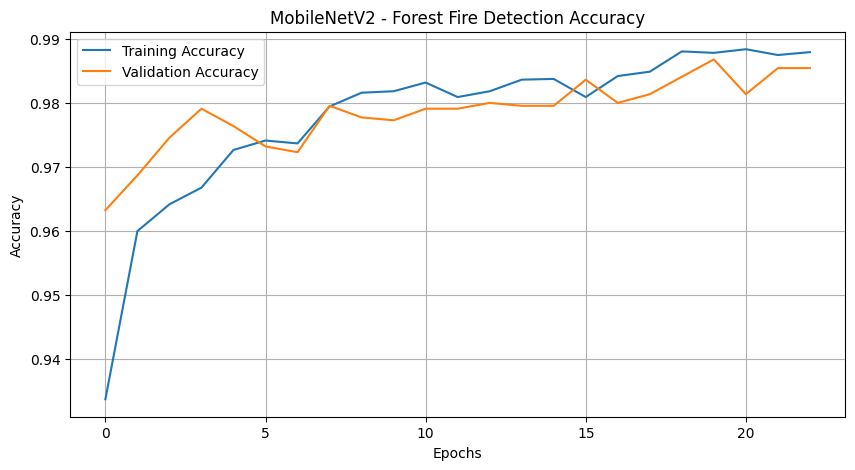

In [35]:
train_acc = (
    history.history["accuracy"]
    + history_fine.history["accuracy"]
)

val_acc = (
    history.history["val_accuracy"]
    + history_fine.history["val_accuracy"]
)

plt.figure(figsize=(10, 5))

plt.plot(train_acc, label="Training Accuracy")

plt.plot(val_acc, label="Validation Accuracy")

plt.title("MobileNetV2 - Forest Fire Detection Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()

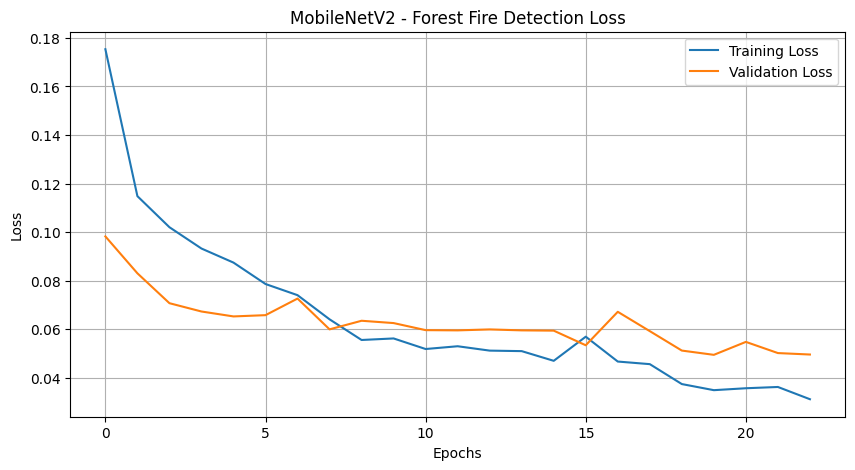

In [36]:
train_loss = (
    history.history["loss"]
    + history_fine.history["loss"]
)

val_loss = (
    history.history["val_loss"]
    + history_fine.history["val_loss"]
)

plt.figure(figsize=(10, 5))

plt.plot(train_loss, label="Training Loss")

plt.plot(val_loss, label="Validation Loss")

plt.title("MobileNetV2 - Forest Fire Detection Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()

In [37]:
y_true = []
y_pred = []

for images, labels in val_data:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    predicted_labels = (
        predictions.ravel() >= 0.5
    ).astype(int)

    y_true.extend(
        labels.numpy().ravel().astype(int)
    )

    y_pred.extend(predicted_labels)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

        FIRE       0.98      0.98      0.98       767
    NON_FIRE       0.99      0.99      0.99      1439

    accuracy                           0.99      2206
   macro avg       0.98      0.99      0.99      2206
weighted avg       0.99      0.99      0.99      2206



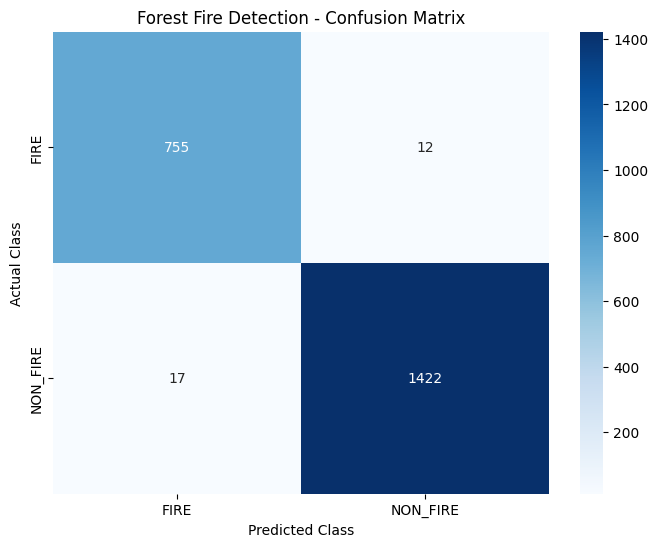

In [38]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.title("Forest Fire Detection - Confusion Matrix")

plt.show()

In [39]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Image Path:", image_path)

print("Image Exists:", os.path.exists(image_path))

Saving FIRE (995).jpg to FIRE (995).jpg
Image Path: FIRE (995).jpg
Image Exists: True


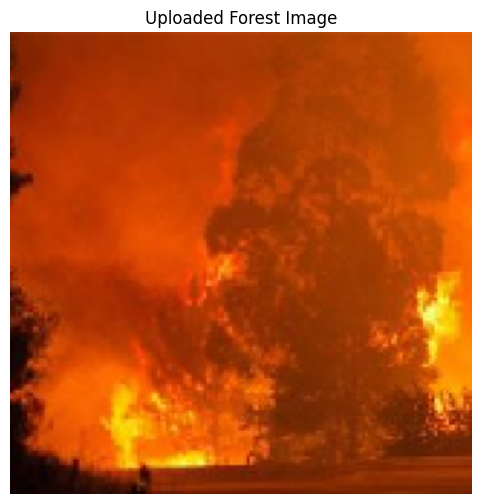

In [40]:
img = load_img(
    image_path,
    target_size=IMAGE_SIZE
)

plt.figure(figsize=(6, 6))

plt.imshow(img)

plt.title("Uploaded Forest Image")

plt.axis("off")

plt.show()

In [41]:
# Convert image into array
img_array = img_to_array(img)

# Add batch dimension
img_array = np.expand_dims(
    img_array,
    axis=0
)

# Predict
prediction = best_model.predict(
    img_array,
    verbose=0
)[0][0]

# Class mapping:
# 0 = FIRE
# 1 = NON_FIRE

if prediction >= 0.5:

    predicted_class = "NON_FIRE"

    confidence = prediction * 100

else:

    predicted_class = "FIRE"

    confidence = (1 - prediction) * 100

print("Image Path:", image_path)

print("Prediction:", predicted_class)

print("Confidence:", round(float(confidence), 2), "%")

Image Path: FIRE (995).jpg
Prediction: FIRE
Confidence: 100.0 %


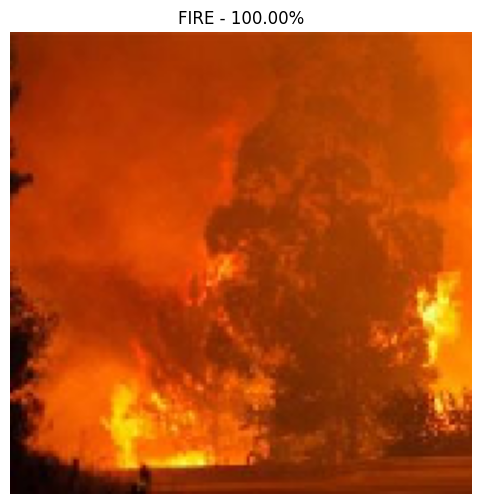

In [42]:
plt.figure(figsize=(7, 6))

plt.imshow(img)

plt.title(
    f"{predicted_class} - {confidence:.2f}%"
)

plt.axis("off")

plt.show()

In [43]:
drive_model_path = ("/content/drive/MyDrive/forest_fire_model.keras")
best_model.save(drive_model_path)

print("Model saved successfully!")
print("Model Path:", drive_model_path)

Model saved successfully!
Model Path: /content/drive/MyDrive/forest_fire_model.keras


In [44]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/forest_fire_model.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>